In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '4' #Evita el aviso de KMeans en Windows; debe ir antes de importar numpy

import numpy as np
import pandas as pd #Permite mostrar tablas como si fuesen de excel
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=12)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

<h1>Aplicación 2: Roles de combate de los Pokémon con K-means</h1>

<h1>Problema</h1>
<p>Los jugadores hablan de "roles" (tanques, atacantes rápidos, muros...), pero el juego no los define. Se intentará averiguar si con K-means se puede descubrir esos roles solo con los números de cada Pokémon.</p>
<ul>
  <li>Cada Pokémon es un punto en 6 dimensiones (sus 6 estadísticas).</li>
  <li>K-means junta a los que tienen estadísticas parecidas.</li>
  <li>El centroide de cada grupo describe al "Pokémon típico" de ese rol.</li>
  <li>Nadie le dice a K-means qué roles existen.</li>
</ul>

<h1>Dataset</h1>
<p>https://github.com/lgreski/pokemonData (basado en Bulbapedia, generaciones 1 a 9)</p>
<ul>
  <li><b>HP:</b> puntos de vida</li>
  <li><b>Attack:</b> ataque físico</li>
  <li><b>Defense:</b> defensa física</li>
  <li><b>Sp. Atk:</b> ataque especial</li>
  <li><b>Sp. Def:</b> defensa especial</li>
  <li><b>Speed:</b> velocidad (quién ataca primero)</li>
  <br>
  <li><b>Total:</b> suma de las 6 estadísticas</li>
  <li><b>Form:</b> forma alternativa del Pokémon (vacío si es la forma normal)</li>
  <li><b>Type1, Type2:</b> tipos del Pokémon (Fuego, Agua, Roca...). No se usan para agrupar, solo para validar al final.</li>
</ul>

In [3]:
df = pd.read_csv('datos/pokemon.csv')

In [4]:
df.head()

,ID,Name,Form,Type1,Type2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation
0,1,Bulbasaur,,Grass,Poison,318,45,49,49,65,65,45,1
1,2,Ivysaur,,Grass,Poison,405,60,62,63,80,80,60,1
2,3,Venusaur,,Grass,Poison,525,80,82,83,100,100,80,1
3,4,Charmander,,Fire,,309,39,52,43,60,50,65,1
4,5,Charmeleon,,Fire,,405,58,64,58,80,65,80,1


In [5]:
df.shape

(1215, 13)

<p>Algunas especies aparecen en varias filas porque tienen formas alternativas (por ejemplo, las formas de Giratina o de Deoxys). Todas las filas de una misma especie comparten el mismo ID, así que se deja solo la primera de cada ID, que en el archivo es la forma normal. Así queda un Pokémon por especie.</p>

In [6]:
df = df.drop_duplicates('ID') #Deja solo la primera fila de cada especie (su forma normal)
df.shape

(1025, 13)

In [7]:
stats = ['HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed']

df[stats].isnull().sum()

HP         0
Attack     0
Defense    0
Sp. Atk    0
Sp. Def    0
Speed      0
dtype: int64

<h1>Preparación de los datos</h1>
<p>Un Legendario tiene todas sus stats altas y un Pokémon sin evolucionar las tiene todas bajas. Si se agrupa con las stats tal cual, K-means separa sobre todo fuertes contra débiles, no roles.</p>
<p>Para encontrar roles se usa el perfil de cada Pokémon: qué fracción de su total tiene en cada stat.</p>

$$p_{ij} = \frac{x_{ij}}{\sum_{j=1}^{6} x_{ij}}$$
<ul>
  <li>i: el Pokémon (fila).</li>
  <li>j: la stat (HP, Attack, Defense, Sp. Atk, Sp. Def o Speed).</li>
  <li>x<sub>ij</sub>: valor de la stat j del Pokémon i.</li>
  <li>El denominador es el total del Pokémon i (la suma de sus 6 stats).</li>
  <li>p<sub>ij</sub>: fracción de su total que el Pokémon i tiene en la stat j. Cada fila suma 1.</li>
</ul>

<p>Así, un Pokémon con mucho de su total en Velocidad es "rápido" sin importar si es fuerte o débil.</p>
<p>Las 6 columnas ya están en la misma escala, por lo que no hace falta <code>StandardScaler</code>.</p>

In [8]:
X = df[stats].values
X = X / X.sum(axis=1)[:, np.newaxis] #Divide cada fila entre su total; np.newaxis convierte el total en columna para poder dividir
X.shape

(1025, 6)

In [9]:
pd.DataFrame(X[:5], columns=stats).round(3) #Perfil de los primeros 5 Pokémon; cada fila suma 1

,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
0,0.142,0.154,0.154,0.204,0.204,0.142
1,0.148,0.153,0.156,0.198,0.198,0.148
2,0.152,0.156,0.158,0.190,0.190,0.152
3,0.126,0.168,0.139,0.194,0.162,0.210
4,0.143,0.158,0.143,0.198,0.160,0.198


In [10]:
X[(df['Name'] == 'Pikachu').values].round(3) #Pikachu tiene 28% de su total en velocidad

array([[0.109, 0.172, 0.125, 0.156, 0.156, 0.281]])

<h1>Número óptimo de clusters</h1>
<p>Se usan los métodos de codo y silueta, ahora con las funciones de Scikit-Learn:</p>
<ul>
  <li>Método del codo: inercia (<code>inertia_</code>) para cada k.</li>
  <li>Coeficiente de silueta: <code>silhouette_score</code>, de −1 a 1; más alto es mejor.</li>
</ul>

In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [12]:
ks = range(2, 11)
inercias = []
siluetas = []

for k in ks:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inercias.append(kmeans.inertia_)
    siluetas.append(silhouette_score(X, kmeans.labels_))

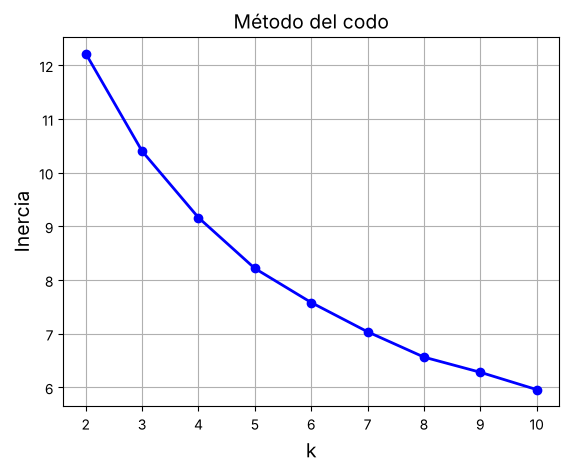

In [13]:
plt.plot(ks, inercias, 'b-o', linewidth=2)
plt.xlabel('k')
plt.ylabel('Inercia')
plt.title('Método del codo')
plt.grid(True)
plt.show()

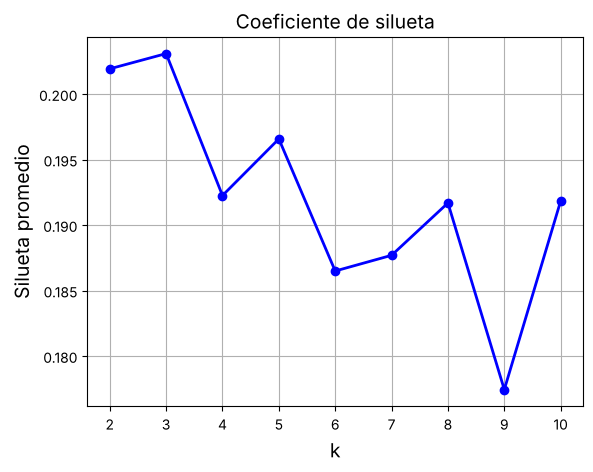

In [14]:
plt.plot(ks, siluetas, 'b-o', linewidth=2)
plt.xlabel('k')
plt.ylabel('Silueta promedio')
plt.title('Coeficiente de silueta')
plt.grid(True)
plt.show()

In [15]:
for i in range(len(ks)):
    print(f'k = {ks[i]:2} -> inercia = {inercias[i]:.3f}, silueta = {siluetas[i]:.3f}')

k =  2 -> inercia = 12.218, silueta = 0.202
k =  3 -> inercia = 10.399, silueta = 0.203
k =  4 -> inercia = 9.161, silueta = 0.192
k =  5 -> inercia = 8.216, silueta = 0.197
k =  6 -> inercia = 7.581, silueta = 0.186
k =  7 -> inercia = 7.036, silueta = 0.188
k =  8 -> inercia = 6.564, silueta = 0.192
k =  9 -> inercia = 6.281, silueta = 0.177
k = 10 -> inercia = 5.959, silueta = 0.192


<p>El codo es suave y la silueta casi no cambia (entre 0.18 y 0.20), así que no marcan un k claro. La más alta es k = 3, pero con 3 grupos solo se separan estilos muy generales; para encontrar roles que combinan stats hacen falta más grupos. Entre k = 7 y k = 8 la silueta es prácticamente igual (0.188 y 0.192).</p>
<p>Se elige k = 7: con k = 8 aparece un grupo extra que mezcla Pokémon de varios roles y solo destaca un poco en Sp. Def (+4.3), es decir, es un grupo de Pokémon equilibrados más que un rol nuevo. </p>
<p>La silueta es baja (~0.2) porque los grupos se traslapan: muchos Pokémon son equilibrados y quedan en la frontera entre dos roles.</p>

<h1>K-means con Scikit-Learn (k = 7)</h1>

In [16]:
k = 7
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)

In [17]:
centros = pd.DataFrame(kmeans.cluster_centers_ * 100, columns=stats) #Centroides en % del total
centros.round(1)

,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
0,14.5,13.8,13.5,20.3,17.2,20.7
1,17.2,14.6,17.3,20.1,19.1,11.8
2,17.3,21.7,16.5,14.9,15.1,14.4
3,36.1,15.0,10.6,12.6,15.1,10.7
4,14.8,20.1,14.0,13.9,13.9,23.3
5,16.8,21.2,26.7,11.6,13.0,10.6
6,12.9,13.8,25.4,13.4,25.2,9.3


<h2>Nombre de cada grupo</h2>
<p>K-means solo entrega el perfil de cada centroide, sin nombre. Cada grupo se nombra por las stats en las que más supera al Pokémon promedio (hasta dos, si lo superan por más de 2 puntos); el nombre de cada combinación lo pone una persona, con el vocabulario de los jugadores.</p>

In [18]:
promedio = X.mean(axis=0) * 100 #Perfil del Pokémon promedio
diferencia = centros - promedio #Puntos porcentuales arriba (+) o abajo (-) del promedio
diferencia.round(1)

,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
0,-2.0,-4.2,-3.5,4.0,0.8,4.8
1,0.7,-3.4,0.3,3.9,2.7,-4.1
2,0.9,3.7,-0.4,-1.3,-1.3,-1.5
3,19.6,-3.1,-6.3,-3.7,-1.3,-5.2
4,-1.7,2.1,-3.0,-2.4,-2.5,7.5
5,0.3,3.2,9.8,-4.7,-3.4,-5.3
6,-3.5,-4.2,8.4,-2.8,8.8,-6.6


In [19]:
nombre_por_combinacion = {('Attack',): 'Atacante físico',
                          ('Attack', 'Speed'): 'Físico rápido',
                          ('Sp. Atk', 'Speed'): 'Especial rápido',
                          ('Sp. Atk', 'Sp. Def'): 'Tanque especial',
                          ('Attack', 'Defense'): 'Tanque físico',
                          ('Defense', 'Sp. Def'): 'Muro',
                          ('HP',): 'Mucha vida'}

nombres = []
for g in range(k):
    fila = diferencia.iloc[g].sort_values(ascending=False) #Stats del centroide g, de mayor a menor diferencia
    destacadas = tuple(sorted([stat for stat in fila.index[:2] if fila[stat] > 2])) #Las 2 mayores que superan al promedio por más de 2 puntos; sorted las pone en orden alfabético, como en el diccionario
    nombres.append(nombre_por_combinacion.get(destacadas, ' + '.join(destacadas))) #Si la combinación no tiene nombre, se usan las stats

nombres

['Especial rápido',
 'Tanque especial',
 'Atacante físico',
 'Mucha vida',
 'Físico rápido',
 'Tanque físico',
 'Muro']

In [20]:
df['Rol'] = [nombres[g] for g in kmeans.labels_] #labels_ dice a qué grupo pertenece cada Pokémon

for rol in nombres:
    cantidad = (df['Rol'] == rol).sum()
    print(f'{rol:18} -> {cantidad} Pokémon')

Especial rápido    -> 185 Pokémon
Tanque especial    -> 195 Pokémon
Atacante físico    -> 295 Pokémon
Mucha vida         -> 23 Pokémon
Físico rápido      -> 177 Pokémon
Tanque físico      -> 93 Pokémon
Muro               -> 57 Pokémon


<h2>Perfil de cada rol</h2>
<p>Cada celda dice cuántos puntos porcentuales está el centroide por arriba (rojo) o por debajo (azul) del Pokémon promedio en esa stat.</p>

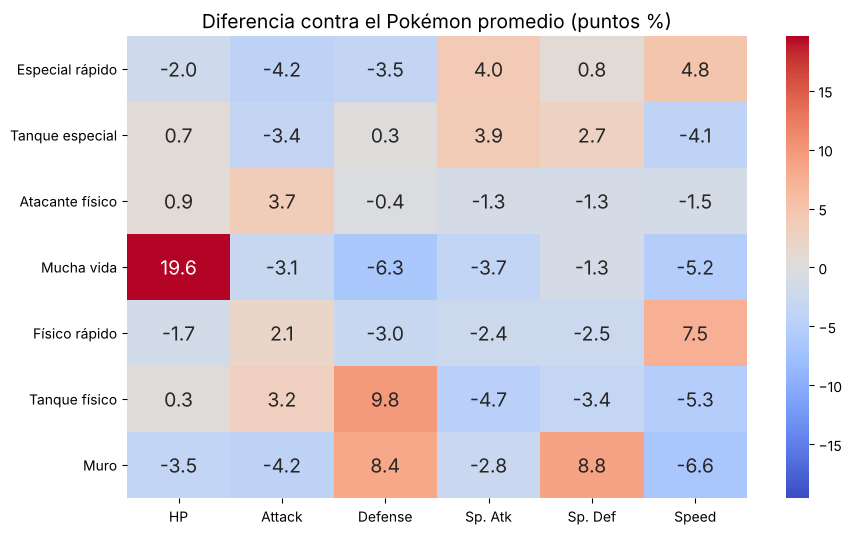

In [21]:
diferencia.index = nombres
limite = np.abs(diferencia.values).max() #Para que el 0 quede en el color neutro

plt.figure(figsize=(10, 6))
sns.heatmap(diferencia, cmap='coolwarm', annot=True, fmt='.1f', vmin=-limite, vmax=limite)
plt.title('Diferencia contra el Pokémon promedio (puntos %)')
plt.show()

<p>Cada rol combina lo que destaca y lo que sacrifica. Tanque físico y Muro tienen mucha Defense, pero el Tanque físico también pega (Attack +3.2) y el Muro no (Attack −4.2) a cambio de mucha Sp. Def. Todos los roles que aguantan son lentos.</p>

<h2>Ejemplos de Pokémon conocidos</h2>

In [22]:
famosos = ['Machamp', 'Pikachu', 'Ninjask', 'Weavile', 'Alakazam', 'Gengar', 'Mewtwo', 'Togekiss', 'Blastoise',
           'Golem', 'Steelix', 'Shuckle', 'Registeel', 'Snorlax', 'Chansey', 'Blissey']

for nombre in famosos:
    rol = df[df['Name'] == nombre]['Rol'].values[0]
    print(f'{nombre:10} -> {rol}')

Machamp    -> Atacante físico
Pikachu    -> Físico rápido
Ninjask    -> Físico rápido
Weavile    -> Físico rápido
Alakazam   -> Especial rápido
Gengar     -> Especial rápido
Mewtwo     -> Especial rápido
Togekiss   -> Tanque especial
Blastoise  -> Tanque especial
Golem      -> Tanque físico
Steelix    -> Tanque físico
Shuckle    -> Muro
Registeel  -> Muro
Snorlax    -> Mucha vida
Chansey    -> Mucha vida
Blissey    -> Mucha vida


<h2>¿Qué aporta K-means frente a una regla simple?</h2>
<p>Sin K-means, se podría darle a cada Pokémon el rol de la stat en la que más supera al promedio. La tabla cruza esa regla (filas) con los roles de K-means (columnas).</p>

In [23]:
regla = [stats[i] for i in np.argmax(X - X.mean(axis=0), axis=1)] #Stat en la que cada Pokémon más supera al promedio

pd.crosstab(pd.Series(regla, name='Stat más destacada'), pd.Series(df['Rol'].values, name='Rol de K-means'))

Rol de K-means,Atacante físico,Especial rápido,Físico rápido,Mucha vida,Muro,Tanque especial,Tanque físico
Stat más destacada,,,,,,,
Attack,157,0,26,0,0,1,11
Defense,34,0,2,0,21,16,76
HP,49,4,0,23,0,36,6
Sp. Atk,29,77,2,0,0,90,0
Sp. Def,4,25,1,0,36,52,0
Speed,22,79,146,0,0,0,0


<p>Esta regla junta Pokémon que juegan de forma muy distinta, porque decide con una sola stat. K-means los separa porque compara el perfil completo:</p>
<ul>
  <li>Speed (247): 146 son rápidos físicos y 79 rápidos especiales.</li>
  <li>Sp. Atk (198): 77 son especiales rápidos (Alakazam, Gengar, Mewtwo) y 90 tanques especiales (Togekiss).</li>
  <li>Defense (149): 76 son tanques físicos que también pegan (Golem, Steelix) y 21 muros que casi no pegan (Shuckle).</li>
</ul>
<p>Estos roles combinan dos stats, así que la regla no puede encontrarlos; K-means los descubre sin que nadie le diga qué combinaciones existen.</p>

<h2>Validación con los tipos</h2>
<p>K-means nunca vio el tipo de los Pokémon. Si los grupos tienen sentido, ciertos tipos deberían caer mucho en el rol que se les asocia en el juego, por ejemplo Tierra, Roca y Acero en los tanques físicos, o Psíquico y Hada en los roles especiales.</p>
<p>Cada fila dice en qué rol cayeron los Pokémon de ese tipo (en %). La última fila es el reparto de todos los Pokémon, para comparar.</p>

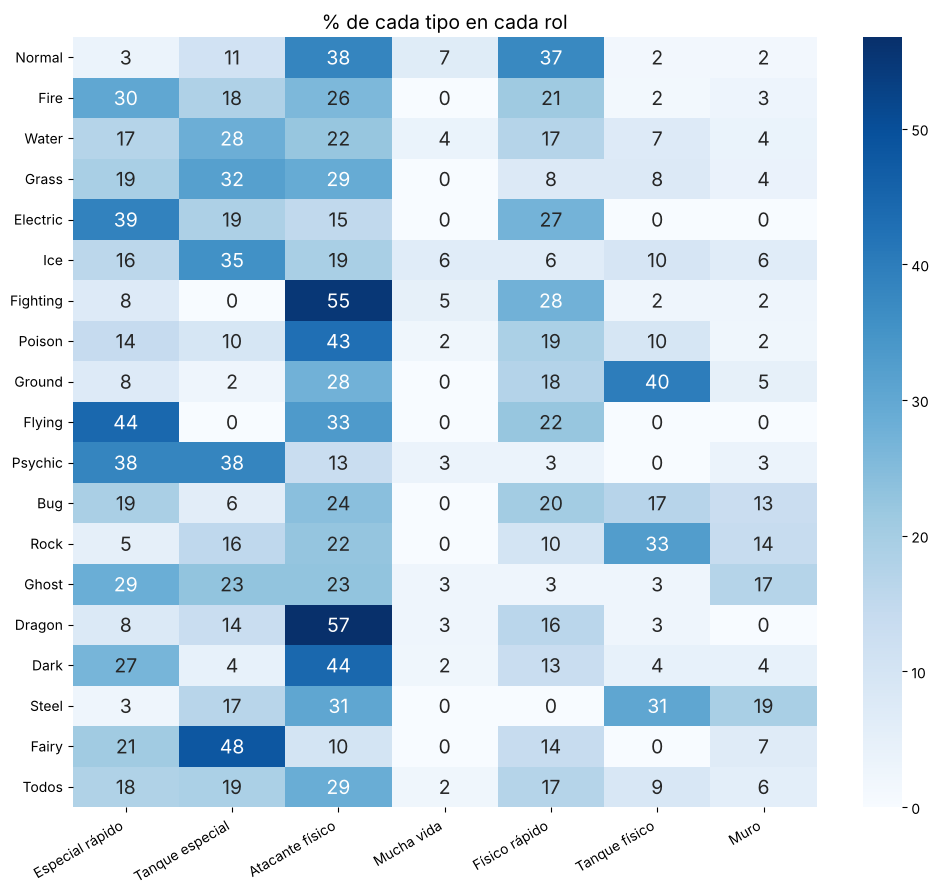

In [24]:
tipos = ['Normal', 'Fire', 'Water', 'Grass', 'Electric', 'Ice', 'Fighting', 'Poison', 'Ground',
         'Flying', 'Psychic', 'Bug', 'Rock', 'Ghost', 'Dragon', 'Dark', 'Steel', 'Fairy'] #Los 18 tipos en el orden oficial del juego

filas = []
for tipo in tipos:
    del_tipo = df[df['Type1'] == tipo]
    filas.append([100 * (del_tipo['Rol'] == rol).sum() / len(del_tipo) for rol in nombres]) #% del tipo que cayó en cada rol

filas.append([100 * (df['Rol'] == rol).sum() / len(df) for rol in nombres]) #Reparto de todos los Pokémon
validacion = pd.DataFrame(filas, columns=nombres, index=tipos + ['Todos'])

plt.figure(figsize=(12, 10))
sns.heatmap(validacion, cmap='Blues', annot=True, fmt='.0f')
plt.xticks(rotation=30, ha='right') #Nombres de los roles inclinados para que no se encimen
plt.yticks(rotation=0) #Nombres de los tipos en horizontal
plt.title('% de cada tipo en cada rol')
plt.show()

<h1>Visualización</h1>
<p>Con 6 dimensiones no se pueden ver todos los datos en una sola gráfica. Se usa <code>pairplot</code> para ver cada par de stats, con cada Pokémon coloreado según su rol.</p>

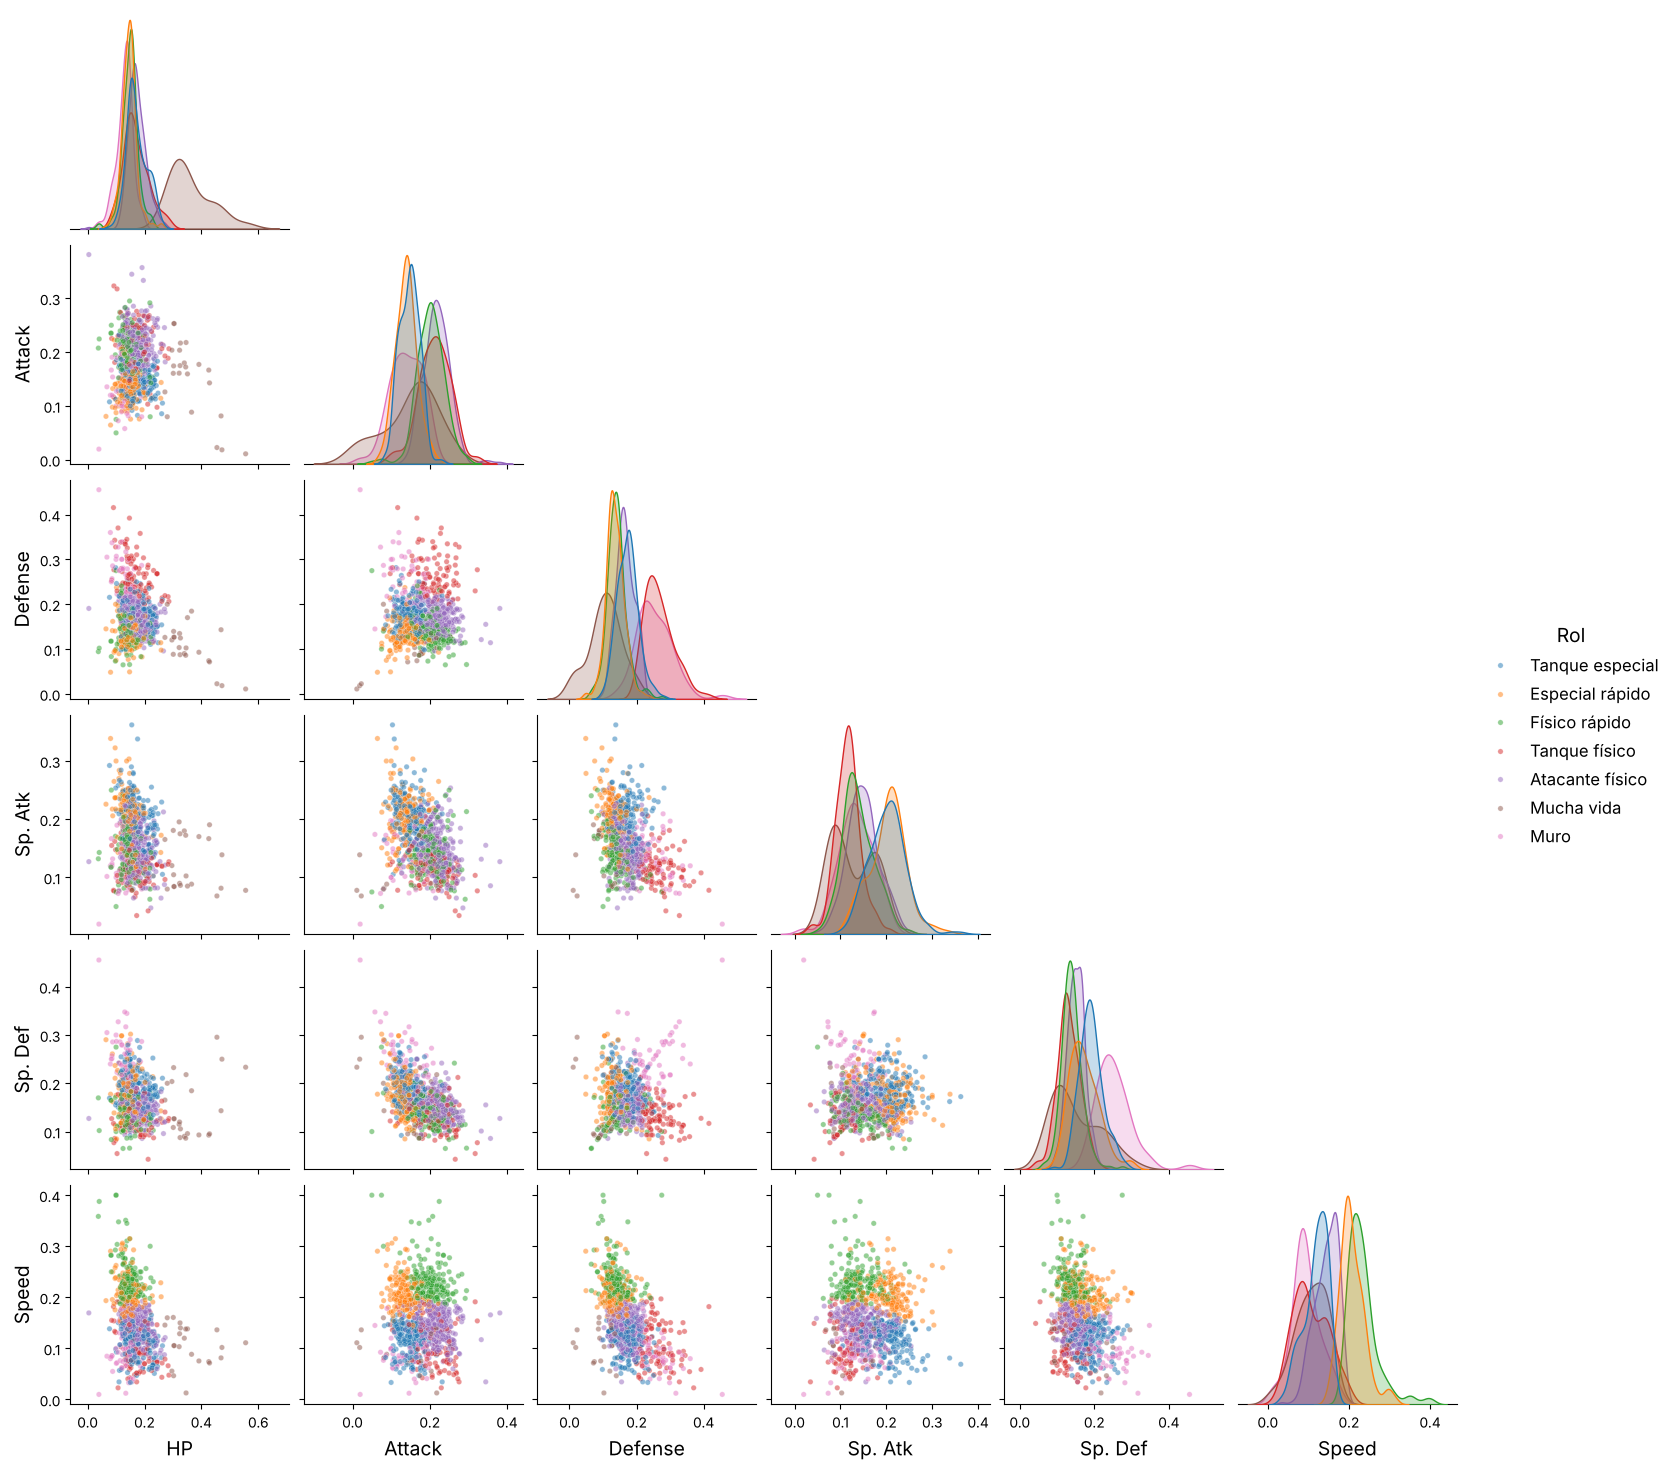

In [25]:
perfil = pd.DataFrame(X, columns=stats)
perfil['Rol'] = df['Rol'].values

sns.pairplot(perfil, hue='Rol', corner=True, plot_kws={'alpha':0.5, 's':15}, diag_kws={'common_norm': False}) #common_norm=False: cada curva de la diagonal se escala por separado, para que los roles con pocos Pokémon también se vean
plt.show()

<p>En la diagonal se ve en qué stat se separa cada rol. En la de Speed, los dos roles rápidos quedan a la derecha; en la de Defense, Tanque físico y Muro; en la de Sp. Def, el Muro; y en la de HP, Mucha vida. En los demás pares los grupos se enciman, porque cada gráfica solo muestra 2 de las 6 dimensiones.</p>

<h1>Conclusiones</h1>
<ul>
  <li>K-means encontró 7 roles solo con el perfil de stats de los 1,025 Pokémon: Atacante físico, Físico rápido, Especial rápido, Tanque especial, Tanque físico, Muro y Mucha vida.</li>
  <li>La mayoría combina dos stats (por ejemplo, Especial rápido = Sp. Atk y Speed; Tanque físico = Defense y Attack). Una regla por la stat más destacada no puede encontrarlos; K-means sí, porque compara el perfil completo.</li>
  <li>Los roles coinciden con el juego aunque K-means nunca vio los tipos: Lucha y Dragón son atacantes físicos, Eléctrico y Psíquico especiales rápidos, Hada tanques especiales, y Tierra, Roca y Acero tanques físicos.</li>
  <li>Usar el perfil (fracción del total) en lugar de las stats tal cual es lo que permite encontrar roles; con las stats tal cual K-means solo separa débiles contra fuertes.</li>
</ul>

<p>Limitaciones: la silueta es baja (~0.2) porque los roles se traslapan; k no tiene una única respuesta (el codo es suave); los nombres de los roles los pone una persona; y K-means asume grupos más o menos redondos y de tamaño parecido, por eso un grupo chico y extremo como Mucha vida (23 Pokémon) puede absorber Pokémon que no son tan extremos.</p>
<p>Se usa solo la forma normal de cada especie. Las formas alternativas (Megaevoluciones, formas regionales, Aegislash, Deoxys...) tienen stats distintas y podrían caer en otro rol, pero incluirlas haría que algunas especies pesaran más que otras.</p>